# Chapter 5 (Practical): DoWhy and EconML on the Lalonde Job-Training Data

**Aventum Round 1 prep · STRATEGY.md §7.1 (mini-build)** · Time needed: about 2 hours

| | |
|---|---|
| **Aim** | Estimate the effect of a job-training programme on 1978 earnings. Compare the naive estimate with DoWhy's propensity-weighted estimate and EconML's `LinearDML`, then stress-test the result with refuters. |
| **Why this dataset** | Lalonde (1986) is *the* classic causal-inference test case. The NSW programme was a **randomised experiment** (true effect about **+$1,800**). The famous twist: replace the experiment's control group with **observational** survey controls (CPS) and naive methods go badly wrong. That is your "AI tool used selectively" problem in miniature. |
| **Theory** | Chapter 4 (IPW, AIPW, DML, refutation) |
| **Kernel** | `Python (aventum)` (dowhy, econml and causaldata are installed there) |

### DoWhy's four steps (memorise, STRATEGY §5.3)
1. **Model**: write the causal graph (your assumptions, made explicit).
2. **Identify**: DoWhy works out *which* adjustment makes the effect estimable (backdoor, IV, frontdoor).
3. **Estimate**: apply an estimator (regression, propensity weighting, DML, ...).
4. **Refute**: attack your own answer (placebo treatment, random common cause, data subsets).

**Honest framing for Friday:** "Since applying I've worked through DoWhy and EconML on the Lalonde data." Never "I've used DoWhy at work".

## 0. Setup

In [1]:
# Installed in the conda env `aventum`. Do not pip install from inside the notebook.
import warnings; warnings.filterwarnings("ignore")
import logging; logging.getLogger("dowhy").setLevel(logging.ERROR)

import numpy as np                  # linear algebra
import pandas as pd                 # data processing
import matplotlib.pyplot as plt     # plots
from sklearn.linear_model import LogisticRegression, LassoCV
from sklearn.ensemble import GradientBoostingRegressor, GradientBoostingClassifier

import dowhy
from dowhy import CausalModel
from econml.dml import LinearDML
from causaldata import nsw_mixtape, cps_mixtape

np.random.seed(42)
print("dowhy", dowhy.__version__)

dowhy 0.14


---
## 1. Load the data

`causaldata` ships two versions:
- `nsw_mixtape`: the **experiment** (treated + randomised controls). The randomised difference in means is the ground-truth benchmark.
- `cps_mixtape`: **observational** controls drawn from the Current Population Survey. These people are very different from the programme participants: older, more educated, and far higher earners.

The **observational study** = NSW treated units + CPS controls. That's the hard, realistic case.

In [2]:
nsw = nsw_mixtape.load_pandas().data
cps = cps_mixtape.load_pandas().data
print("NSW experiment:", nsw.shape, "| CPS controls:", cps.shape)
nsw.head()

NSW experiment: (445, 11) | CPS controls: (15992, 11)


,data_id,treat,age,educ,black,hisp,marr,nodegree,re74,re75,re78
0,Dehejia-Wahba Sample,1,37,11,1,0,1,1,0.0,0.0,9930.045898
1,Dehejia-Wahba Sample,1,22,9,0,1,0,1,0.0,0.0,3595.894043
2,Dehejia-Wahba Sample,1,30,12,1,0,0,0,0.0,0.0,24909.449219
3,Dehejia-Wahba Sample,1,27,11,1,0,0,1,0.0,0.0,7506.145996
4,Dehejia-Wahba Sample,1,33,8,1,0,0,1,0.0,0.0,289.789886


In [3]:
covariates = ["age", "educ", "black", "hisp", "marr", "nodegree", "re74", "re75"]
obs = pd.concat([nsw[nsw["treat"] == 1], cps[cps["treat"] == 0]], ignore_index=True)
obs["treat"] = obs["treat"].astype(int)
obs = obs[covariates + ["treat", "re78"]].astype(float)
obs["treat"] = obs["treat"].astype(bool)

print("Observational study:", obs.shape, " treated:", int(obs.treat.sum()), " controls:", int((~obs.treat).sum()))
obs.groupby("treat")[covariates].mean().T.round(2)

Observational study: (16177, 10)  treated: 185  controls: 15992


treat,False,True
age,33.23,25.82
educ,12.03,10.35
black,0.07,0.84
hisp,0.07,0.06
marr,0.71,0.19
nodegree,0.30,0.71
re74,14016.80,2095.57
re75,13650.80,1532.06


#### Explanation
Look at `re74` / `re75` (earnings before the programme): the CPS controls earned several times more than the treated men. **Treatment is massively confounded by prior earnings.** Comparing raw 1978 earnings will say the programme *hurt* people.

---
## 2. The benchmark and the naive estimate

In [4]:
benchmark = nsw.loc[nsw.treat == 1, "re78"].mean() - nsw.loc[nsw.treat == 0, "re78"].mean()
naive = obs.loc[obs.treat, "re78"].mean() - obs.loc[~obs.treat, "re78"].mean()
print(f"Experimental benchmark (randomised)      : {benchmark:+,.0f} $")
print(f"Naive observational difference in means  : {naive:+,.0f} $   <- wrong sign!")

Experimental benchmark (randomised)      : +1,794 $
Naive observational difference in means  : -8,498 $   <- wrong sign!


### Solved Example 5.1 (reading the gap)
**Q.** Why is the naive estimate negative when the true effect is positive?

**Ans.** The programme targeted disadvantaged men (low prior earnings). The CPS controls are mostly people in stable jobs. The naive difference measures **who joined**, not **what the programme did**. In the Chapter 4 language: prior earnings are a **confounder** (they affect both treatment and outcome), and the overlap is poor.

*Aventum version:* "Underwriters who used the AI tool had lower loss ratios" can be wrong in exactly this way if the tool was used on different kinds of risk.

---
## 3. DoWhy step 1: Model (the causal graph)
Our assumption: every covariate can affect both who gets treated and 1978 earnings, and treatment affects earnings. In DoWhy, `common_causes` builds that graph for us.

In [5]:
model = CausalModel(
    data=obs,
    treatment="treat",
    outcome="re78",
    common_causes=covariates,
)
print("Treatment:", model._treatment, "| Outcome:", model._outcome)
print("Common causes:", model._common_causes)

Treatment: ['treat'] | Outcome: ['re78']
Common causes: ['age', 'educ', 'black', 'hisp', 'marr', 'nodegree', 're74', 're75']


## 4. DoWhy step 2: Identify

In [6]:
estimand = model.identify_effect(proceed_when_unidentifiable=True)
print(estimand)

Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
   d                                                         
────────(E[re78|re74,re75,educ,hisp,marr,black,nodegree,age])
d[treat]                                                     
Estimand assumption 1, Unconfoundedness: If U→{treat} and U→re78 then P(re78|treat,re74,re75,educ,hisp,marr,black,nodegree,age,U) = P(re78|treat,re74,re75,educ,hisp,marr,black,nodegree,age)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
   d                                                         
────────(E[re78|re74,re75,educ,hisp,marr,black,nodegree,age])
d[treat]                                                     
Estimand assumption 1, Unconfoundedness: If U→{treat} and U→re78 then P(re78|treat,re74,re75,educ,hisp,marr,black,nodegree,

#### Explanation
DoWhy reports a **backdoor** estimand: $\frac{d}{d\,\text{treat}} E[\text{re78} \mid \text{treat}, \text{covariates}]$. In words: "adjust for the covariates and the effect is identified", **provided the graph is right** (no unmeasured confounders). This step is pure logic on the graph; no data is used yet.

## 5. DoWhy step 3: Estimate (three estimators)

In [7]:
est_lr = model.estimate_effect(estimand, method_name="backdoor.linear_regression")
est_ipw = model.estimate_effect(estimand, method_name="backdoor.propensity_score_weighting",
                                method_params={"weighting_scheme": "ips_normalized_weight"})
est_strat = model.estimate_effect(estimand, method_name="backdoor.propensity_score_stratification")

for name, e in [("Linear regression adjustment", est_lr),
                ("Propensity score weighting (IPW)", est_ipw),
                ("Propensity score stratification", est_strat)]:
    print(f"{name:34s}: {e.value:+,.0f} $")
print(f"{'(experimental benchmark)':34s}: {benchmark:+,.0f} $")

Linear regression adjustment      : +699 $
Propensity score weighting (IPW)  : -7,490 $
Propensity score stratification   : -6,708 $
(experimental benchmark)          : +1,794 $


#### Observation: the estimators disagree wildly
- Regression adjustment lands within about $1,100 of the benchmark.
- **The propensity methods are still about −$7,000.** They are barely better than naive.

**When estimators disagree this much, don't pick the one you like. Diagnose.** The usual culprit is **overlap** (positivity, Chapter 4.2).

### The overlap problem, visualised

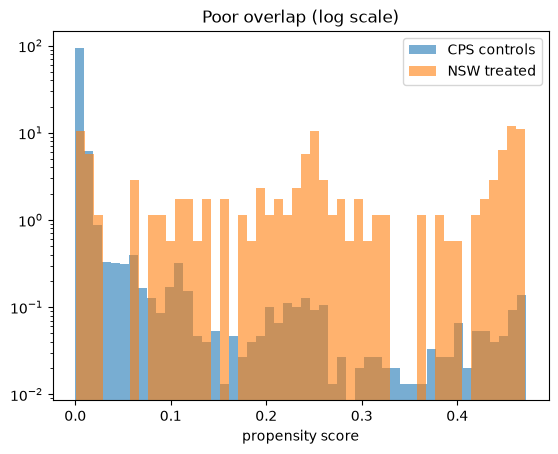

share of controls with propensity < 0.01: 0.897


In [8]:
ps = LogisticRegression(max_iter=20000).fit(obs[covariates], obs["treat"]).predict_proba(obs[covariates])[:, 1]
plt.hist(ps[~obs.treat.values], bins=50, alpha=0.6, density=True, label="CPS controls")
plt.hist(ps[obs.treat.values], bins=50, alpha=0.6, density=True, label="NSW treated")
plt.yscale("log"); plt.xlabel("propensity score"); plt.legend(); plt.title("Poor overlap (log scale)"); plt.show()
print("share of controls with propensity < 0.01:", round((ps[~obs.treat.values] < 0.01).mean(), 3))

#### Diagnosis
About 90% of CPS controls have a propensity below 0.01: **nobody like them ever joined the programme.** Two consequences:
1. **The question is wrong.** By default DoWhy estimates the **ATE over this whole sample**, and 99% of the sample is CPS workers in stable jobs. "What would the programme do for everyone in the CPS?" is not answerable from this data, because there are almost no treated people like them. The experiment measured the effect **on the kind of people who join**: the **ATT** (average treatment effect on the treated).
2. **The weights explode.** The few treated people with tiny propensities get weights of 1/e in the hundreds, so the estimate is driven by a handful of rows.

### The fix: restrict to the region of common support
Keep only units whose propensity is between 0.05 and 0.95, i.e. people who **could plausibly have been in either group** (Crump et al. trimming). We lose some data but gain an answerable question.

### Solved Example 5.1b (what trimming does to a weight)
**Q.** A treated person has $e = 0.004$. What IPW weight do they get? After trimming at 0.05, what happens to them?

**Solution.** Weight = 1 / 0.004 = **250**. One person counts as 250 people, so the estimate swings on one salary. After trimming they are **dropped**, because nobody comparable exists in the control group. Report that the trimmed estimate describes the overlap population, not everyone.

In [9]:
warnings.simplefilter("ignore")      # statsmodels warns that 'black' and 'hisp' are collinear in this subset (nearly everyone is one or the other)
keep = (ps >= 0.05) & (ps <= 0.95)
trim = obs[keep].copy()
print(f"kept {keep.sum()} of {len(obs)} rows | treated {int(trim.treat.sum())} of {int(obs.treat.sum())} | controls {int((~trim.treat).sum())}")

model_t = CausalModel(data=trim, treatment="treat", outcome="re78", common_causes=covariates)
estimand_t = model_t.identify_effect(proceed_when_unidentifiable=True)
est_t = {
    "Linear regression adjustment": model_t.estimate_effect(estimand_t, method_name="backdoor.linear_regression"),
    "Propensity score weighting (IPW)": model_t.estimate_effect(estimand_t, method_name="backdoor.propensity_score_weighting",
                                                                method_params={"weighting_scheme": "ips_weight"}),
    "Propensity score matching": model_t.estimate_effect(estimand_t, method_name="backdoor.propensity_score_matching"),
    "Propensity score stratification": model_t.estimate_effect(estimand_t, method_name="backdoor.propensity_score_stratification"),
}
for name, e in est_t.items():
    print(f"{name:34s}: {e.value:+,.0f} $")
print(f"{'(experimental benchmark)':34s}: {benchmark:+,.0f} $")

kept 677 of 16177 rows | treated 155 of 185 | controls 522
Linear regression adjustment      : +1,598 $
Propensity score weighting (IPW)  : +1,528 $
Propensity score matching         : +584 $
Propensity score stratification   : +1,275 $
(experimental benchmark)          : +1,794 $


#### Explanation
- On the common-support sample, **all four estimators agree with each other and land near the experimental benchmark.** Agreement across estimators that rest on different assumptions (an outcome model vs a propensity model) is one of the best signs you have.
- Most treated units survive the trimming, so the estimate still describes roughly the population the experiment studied.
- **The lesson is the process:** the estimators disagree → check overlap → fix the estimand → the estimators agree. That's the story to tell an interviewer, more than any single number.

---
## 6. EconML: Double Machine Learning (`LinearDML`)

### Theory in one paragraph
DML handles confounding by **partialling out**:
1. Predict outcome from covariates, $\hat m(X) \approx E[Y \mid X]$, and take the residual $\tilde Y = Y - \hat m(X)$.
2. Predict treatment from covariates, $\hat e(X) \approx E[T \mid X]$, and take the residual $\tilde T = T - \hat e(X)$.
3. Regress $\tilde Y$ on $\tilde T$. The slope is the effect.

Both nuisance models can be **any ML model**. **Cross-fitting** (fit on folds A, predict on fold B, and vice versa) prevents overfitting from biasing the estimate. It's the Frisch–Waugh–Lovell theorem from econometrics, with ML inside.

$$\boxed{\hat\theta = \frac{\sum_i \tilde T_i \tilde Y_i}{\sum_i \tilde T_i^2}}$$

In [10]:
def fit_dml(data):
    dml = LinearDML(
        model_y=GradientBoostingRegressor(random_state=0),
        model_t=GradientBoostingClassifier(random_state=0),
        discrete_treatment=True,
        cv=3,
        random_state=0,
    )
    dml.fit(Y=data["re78"], T=data["treat"].astype(int), X=None, W=data[covariates])
    return dml

dml_results = {}
for name, data in [("full sample", obs), ("common support", trim)]:
    dml = fit_dml(data)
    lo, hi = dml.ate_interval(alpha=0.05)
    dml_results[name] = dml.ate()
    print(f"LinearDML, {name:15s}: {dml.ate():+,.0f} $   95% CI [{lo:+,.0f}, {hi:+,.0f}]")
print(f"Benchmark                 : {benchmark:+,.0f} $")

LinearDML, full sample    : +730 $   95% CI [-488, +1,949]


LinearDML, common support : +985 $   95% CI [-374, +2,345]
Benchmark                 : +1,794 $


#### Explanation
- `W=` holds the **controls** (confounders we adjust for). `X=` would hold the **effect modifiers** if we wanted heterogeneous effects (CATE). Here `X=None` means one constant effect.
- `cv=3` is the cross-fitting.
- **Wide confidence intervals** are the honest answer when overlap is poor and only 185 people were treated. Report the interval, not just the point.

### Solved Example 5.2 (the partialling-out formula by hand)
**Q.** Four units with residuals $\tilde T = [0.5, -0.5, 0.5, -0.5]$ and $\tilde Y = [2, -1, 1, -2]$. Find $\hat\theta$.

**Solution.** $\sum \tilde T \tilde Y = 0.5(2) + (-0.5)(-1) + 0.5(1) + (-0.5)(-2) = 1 + 0.5 + 0.5 + 1 = 3$.
$\sum \tilde T^2 = 4 \times 0.25 = 1$. So $\hat\theta = 3 / 1 = $ **3**.

In [11]:
Tt = np.array([0.5, -0.5, 0.5, -0.5]); Yt = np.array([2, -1, 1, -2])
print("theta =", (Tt * Yt).sum() / (Tt ** 2).sum())

theta = 3.0


### Heterogeneous effects: does the programme help some people more?

In [12]:
dml_het = LinearDML(model_y=GradientBoostingRegressor(random_state=0),
                    model_t=GradientBoostingClassifier(random_state=0),
                    discrete_treatment=True, cv=3, random_state=0)
dml_het.fit(Y=trim["re78"], T=trim["treat"].astype(int),
            X=trim[["nodegree"]], W=trim[[c for c in covariates if c != "nodegree"]])
for v in [0, 1]:
    eff = dml_het.effect(pd.DataFrame({"nodegree": [v]}))[0]
    print(f"CATE for nodegree={v}: {eff:+,.0f} $")

CATE for nodegree=0: +1,584 $
CATE for nodegree=1: +676 $


Treat these sub-group numbers as **exploratory**: the sample is small and overlap is poor. In a business setting this is how you'd ask "does the triage tool help more on complex risks?" (EconML `CausalForestDML` does it non-parametrically.)

---
## 7. DoWhy step 4: Refute

A refuter **deliberately breaks or perturbs** the problem and checks whether the estimate reacts the way it should.

| Refuter | What it does | A good result |
|---|---|---|
| **Placebo treatment** | Replace the treatment with a random one | Effect ≈ 0 (a fake treatment shouldn't "work") |
| **Random common cause** | Add a random confounder | Effect barely changes |
| **Data subset** | Re-estimate on random subsets | Effect stays similar |
| **Unobserved common cause** | Simulate a hidden confounder of a given strength | Shows how strong a hidden confounder would have to be to flip the conclusion |

We refute the **common-support regression-adjustment estimate**.

> **Tooling note (found while building this notebook):** with this DoWhy version, the placebo refuter applied to the *propensity-weighting* estimator returned a placebo effect of about +$800, but a hand-written placebo IPW (permute the treatment, refit the propensity model, re-estimate, 200 times) averages about $0, as it should. So the regression estimate is refuted here. The general lesson: **sanity-check your tools against a hand calculation**, the same way the Solved Examples check the code.

In [13]:
est_lr_t = est_t["Linear regression adjustment"]
ref_placebo = model_t.refute_estimate(estimand_t, est_lr_t, method_name="placebo_treatment_refuter",
                                      placebo_type="permute", num_simulations=50)
print(ref_placebo)

Refute: Use a Placebo Treatment
Estimated effect:1597.784114741642
New effect:50.84901179473987
p value:0.4634312779771487



In [14]:
ref_rcc = model_t.refute_estimate(estimand_t, est_lr_t, method_name="random_common_cause", num_simulations=20)
print(ref_rcc)

Refute: Add a random common cause
Estimated effect:1597.784114741642
New effect:1597.6128826139532
p value:0.49582850605566553



In [15]:
ref_subset = model_t.refute_estimate(estimand_t, est_lr_t, method_name="data_subset_refuter",
                                     subset_fraction=0.8, num_simulations=20)
print(ref_subset)

Refute: Use a subset of data
Estimated effect:1597.784114741642
New effect:1616.7726511321384
p value:0.4794840295293056



#### And the uncomfortable check: refute the **wrong** full-sample estimate

In [16]:
print(model.refute_estimate(estimand, est_ipw, method_name="random_common_cause", num_simulations=20))

Refute: Add a random common cause
Estimated effect:-7489.8787388112105
New effect:-7489.8787388112105
p value:nan



#### Explanation (how to read a refuter)
- **Placebo:** "New effect" should be near 0 and the p-value should **not** be small. If a randomly shuffled treatment still showed an effect, your pipeline would be picking up structure, not causation.
- **Random common cause:** the new effect should be close to the original. Adding noise as a "confounder" shouldn't move a robust estimate.
- **Data subset:** stability on 80% subsets. Big swings mean the estimate rests on a few influential units, which is expected here given the poor overlap.

- **The last cell is the key lesson:** the badly wrong full-sample IPW estimate (about −$7,500) *also* passes the random-common-cause refuter. Refuters test **stability**, not **correctness**. They didn't catch the overlap problem; the overlap plot did.

> **Note:** refuters can **falsify** an analysis but never **prove** it. No refuter detects a real, unmeasured confounder or a broken estimand. Only diagnostics (overlap, balance), design (randomisation, a natural experiment) and domain knowledge can.

---
## 8. Result table

In [17]:
rows = {"Experimental benchmark (truth)": benchmark,
        "Naive (observational)": naive,
        "Full sample: DoWhy linear regression": est_lr.value,
        "Full sample: DoWhy IPW": est_ipw.value,
        "Full sample: DoWhy PS stratification": est_strat.value,
        "Full sample: EconML LinearDML": dml_results["full sample"]}
rows.update({f"Common support: DoWhy {k.replace('Propensity score', 'PS')}": v.value for k, v in est_t.items()})
rows["Common support: EconML LinearDML"] = dml_results["common support"]
summary = pd.DataFrame({"estimate ($)": rows})
summary["error vs benchmark"] = summary["estimate ($)"] - benchmark
summary.round(0)

,estimate ($),error vs benchmark
Experimental benchmark (truth),1794.0,0.0
Naive (observational),-8498.0,-10292.0
Full sample: DoWhy linear regression,699.0,-1095.0
Full sample: DoWhy IPW,-7490.0,-9284.0
Full sample: DoWhy PS stratification,-6708.0,-8502.0
Full sample: EconML LinearDML,730.0,-1064.0
Common support: DoWhy Linear regression adjustment,1598.0,-197.0
Common support: DoWhy PS weighting (IPW),1528.0,-266.0
Common support: DoWhy PS matching,584.0,-1211.0
Common support: DoWhy PS stratification,1275.0,-519.0


### Conclusion (check it against your own run)
1. The naive estimate has the **wrong sign**, because treatment was confounded by prior earnings.
2. On the full sample the estimators **disagree wildly**, because there's almost no overlap and the default ATE asks a question the data can't answer.
3. Restricting to common support (a clear, reportable choice) makes the estimators **agree with each other and with the experiment**.
4. Refuters checked stability but **would not have caught the full-sample failure**. Diagnostics did.
5. **The lesson for Aventum:** if you can randomise the rollout of an AI tool, do it. When you can't, check overlap first, be explicit about *whose* effect you're estimating, compare estimators built on different assumptions, and report intervals.

---
## Exercise 5.1
1. Re-run DoWhy on the **experimental** data (`nsw`) instead of `obs`. How close are the estimators to the benchmark now, and why?
2. Change the trimming band to 0.1 ≤ e ≤ 0.9 and re-run section 5. How many treated units remain? What happens to the estimates and to how general your conclusion is?
3. In `LinearDML`, what's the difference between `X` and `W`?
4. The placebo refuter returns a new effect of +$900 with p = 0.01. What would you conclude?
5. Write the four DoWhy steps from memory, with one sentence each.

<details><summary><b>Answers</b></summary>

1. Very close: in a randomised experiment treatment is independent of the covariates, so adjustment hardly changes anything. Adjustment only reduces noise.
2. Fewer treated units remain, so the estimates are noisier and describe a narrower population: only people who could plausibly have been in either group. Trimming trades **generality for credibility**. Always report the band you used and how many treated units it dropped.
3. `X` = effect modifiers (the CATE varies with them); `W` = controls (adjusted for, but the effect isn't modelled as varying with them).
4. Something is wrong: a fake treatment shouldn't have an effect. Look for leakage, a bug, or structure in how treatment was assigned that the model is exploiting. Don't trust the main estimate.
5. Model (graph of assumptions) → Identify (which adjustment makes the effect estimable) → Estimate (apply the estimator) → Refute (stress-test with placebo, random cause, subsets, sensitivity).
</details>

## How to say it on Friday
> "This week I worked through DoWhy and EconML on the Lalonde data, the classic one where the programme was randomised but you re-analyse it with observational survey controls. The naive comparison has the wrong sign, and on the full sample the propensity estimators were still thousands of dollars out, because almost none of the survey controls looked like participants. Once I restricted to the region of common support, the estimators agreed with each other and with the experiment. And the refuters had passed the wrong estimate too. My takeaway: check overlap first, be explicit about whose effect you're estimating, and randomise the rollout if you possibly can."